# Data Inspection

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [11]:
orders= pd.read_csv('olist_orders_dataset.csv')
customers= pd.read_csv('olist_customers_dataset.csv')
geolocation= pd.read_csv('olist_geolocation_dataset.csv')
products= pd.read_csv('olist_products_dataset.csv')
seller= pd.read_csv('olist_sellers_dataset.csv')
order_items=pd.read_csv('olist_order_items_dataset.csv')

In [12]:
orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [13]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [14]:
orders.shape

(99441, 8)

In [15]:
orders['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [16]:
#only keep the deliverd (so the model learns from real cases)
order_filter= (orders['order_status'] == 'delivered')
orders_cleaned= orders[order_filter].copy()

In [17]:
orders_cleaned.head(5)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [18]:
orders_cleaned.dropna(subset=['order_delivered_customer_date'],inplace=True)

In [19]:
orders_cleaned.isnull().sum()

order_id                          0
customer_id                       0
order_status                      0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_carrier_date      1
order_delivered_customer_date     0
order_estimated_delivery_date     0
dtype: int64

In [20]:
#convert to dates
orders_cleaned['order_purchase_timestamp']= pd.to_datetime(orders_cleaned['order_purchase_timestamp'])
orders_cleaned['order_approved_at']= pd.to_datetime(orders_cleaned['order_approved_at'])
orders_cleaned['order_delivered_carrier_date']= pd.to_datetime(orders_cleaned['order_delivered_carrier_date'])
orders_cleaned['order_estimated_delivery_date']= pd.to_datetime(orders_cleaned['order_estimated_delivery_date'])
orders_cleaned['order_delivered_customer_date']= pd.to_datetime(orders_cleaned['order_delivered_customer_date'])

In [21]:
orders_cleaned.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [22]:
#function for stting delivery states ( ontime, late, early) comparing estimates and actual dates
def delivery_stat(estimated,actual):
    actual= actual.date()
    estimated=estimated.date()
    if(estimated==actual):
        return 'Ontime'
    elif (estimated>actual):
        return 'Early'
    else:
        return 'Delay'

orders_cleaned['delivery_status']= orders_cleaned.apply(lambda row: delivery_stat(
    row['order_estimated_delivery_date'],
    row['order_delivered_customer_date']
),  axis=1
                                                       )

In [23]:
deliv_stat=orders_cleaned['delivery_status'].value_counts(normalize=True) * 100

### Delivery On Time Percentage (comapred to estimated)

Text(0.5, 1.0, 'Delivery Status in Percentages')

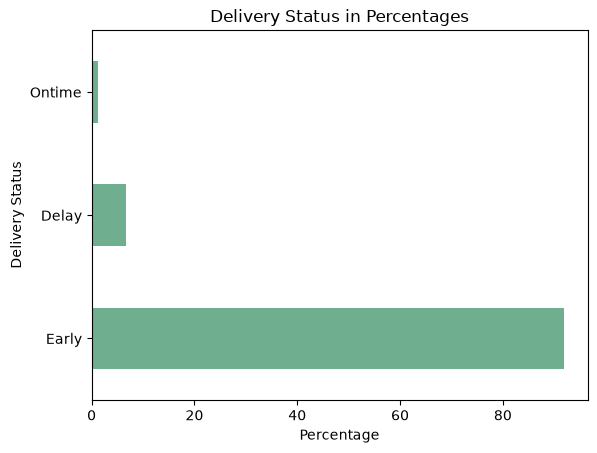

In [24]:
import matplotlib.pyplot as plt
deliv_stat.plot(kind='barh',color='#6FAF8F');
plt.xlabel('Percentage')
plt.ylabel('Delivery Status')
plt.title('Delivery Status in Percentages')
#91.9% comes before the estimated 

In [25]:
#total delivery duratoion in days (from the customer orders until its deliverd
orders_cleaned['delivery_duration']= (orders_cleaned['order_delivered_customer_date'] - orders_cleaned['order_purchase_timestamp']).dt.total_seconds()/86400
orders_cleaned['fulfillment_duration']= (orders_cleaned['order_delivered_carrier_date'] - orders_cleaned['order_approved_at']).dt.total_seconds()/86400
orders_cleaned['shipping_duration']= (orders_cleaned['order_delivered_customer_date'] - orders_cleaned['order_delivered_carrier_date']).dt.total_seconds()/86400

In [26]:
orders_cleaned[['delivery_duration','fulfillment_duration','shipping_duration']].describe()

,delivery_duration,fulfillment_duration,shipping_duration
count,96470.000000,96455.000000,96469.000000
mean,12.558217,2.799049,9.330297
std,9.546156,3.537173,8.759924
min,0.533414,-171.219005,-16.096169
25%,6.766204,0.874207,4.100046
50%,10.217477,1.815810,7.099769
75%,15.720182,3.574931,12.028646
max,209.628611,125.762569,205.190972


In [27]:
orders_cleaned['delivery_diff']= (orders_cleaned['order_delivered_customer_date'].dt.normalize()-
orders_cleaned['order_estimated_delivery_date'].dt.normalize()).dt.days

In [28]:
orders_cleaned.groupby('delivery_status')['delivery_diff'].mean()

delivery_status
Delay     10.620141
Early    -13.707177
Ontime     0.000000
Name: delivery_diff, dtype: float64

In [29]:
orders_cleaned.groupby('delivery_status')['delivery_diff'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

,count,mean,median,min,max
delivery_status,,,,,
Delay,6534,10.620141,7.0,1,188
Early,88644,-13.707177,-13.0,-147,-1
Ontime,1292,0.000000,0.0,0,0


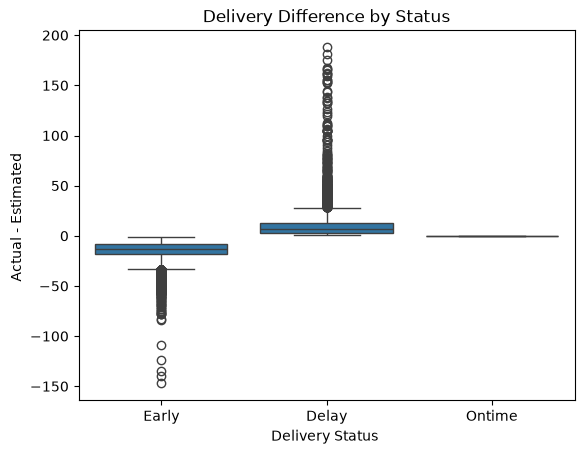

In [30]:
#plotting to check ouliers
sns.boxplot(
    data=orders_cleaned, x='delivery_status',y='delivery_diff'
)
plt.title('Delivery Difference by Status')
plt.ylabel('Actual - Estimated ')
plt.xlabel('Delivery Status ');

### Geoloc dataset

In [31]:
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [32]:
geolocation.duplicated().sum()
geolocation.drop_duplicates(inplace=True)

In [33]:
geolocation.duplicated().sum()


np.int64(0)

In [34]:
geolocation.isnull().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

In [35]:
geolocation['geolocation_zip_code_prefix'].nunique()

19015

In [36]:
#remove outside brazil 
geolocation.drop( geolocation[
        ~geolocation['geolocation_lat'].between(-34, 6) |
        ~geolocation['geolocation_lng'].between(-74, -34)
    ].index,
    inplace=True
)

In [37]:
geolocation.shape[0]

738299

In [38]:
#group the simmilar zip codes with mean 
geo_cleaned= geolocation.groupby('geolocation_zip_code_prefix')[['geolocation_lat','geolocation_lng']].mean()

In [39]:
geo_cleaned.shape

(19010, 2)

### Customers Dataset

In [40]:
customers.head()
customers.info() #use customer_zip_code_prefix (to match with geo table)
customers.duplicated().sum() #0
customers.isnull().sum() #0

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB


customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [41]:
#merge with geo to know customer order area
#left= keep all customers 
customer_cleaned = customers.merge(geo_cleaned,left_on='customer_zip_code_prefix',
right_on= 'geolocation_zip_code_prefix', how='left')

In [42]:
customer_cleaned.isnull().sum() #278 no data (will impute later

customer_id                   0
customer_unique_id            0
customer_zip_code_prefix      0
customer_city                 0
customer_state                0
geolocation_lat             279
geolocation_lng             279
dtype: int64

In [43]:
customer_cleaned['customer_city'].nunique() #4119
customer_cleaned['customer_state'].nunique() #27
customer_cleaned['customer_id'].nunique() #99441 customers


99441

In [44]:
customer_cleaned['customer_state'].value_counts().head(10) #top 10 states

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64

### Seller Dataset

In [45]:
seller.head()
seller.info()
seller.duplicated().sum() #0
seller.isnull().sum() #0

<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 230.3 KB


seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [46]:
#merge with zip to know from where each
seller_cleaned = seller.merge(geo_cleaned,left_on='seller_zip_code_prefix',
right_on= 'geolocation_zip_code_prefix', how='left')

In [47]:
seller_cleaned.isnull().sum() #7 no data (will impute later

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
geolocation_lat           7
geolocation_lng           7
dtype: int64

In [48]:
seller_cleaned['seller_id'].nunique() #3095 sellers

3095

In [49]:
seller_cleaned['seller_city'].nunique() #611
seller_cleaned['seller_state'].nunique() #23

23

In [50]:
#top 10 states
seller_cleaned['seller_state'].value_counts().head(10)

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: count, dtype: int64

### Product Dataset

In [51]:
products.head()
products.info()
products.describe()
products.duplicated().sum() #zero
products.isnull().sum() #impute later


<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 3.7 MB


product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [52]:
products.shape

(32951, 9)

In [53]:
#adding new features
#col1: max cum (largest dimention of a product)
products_cleaned = products.copy()
products_cleaned['product_max_dim_cm']= products_cleaned[['product_length_cm','product_height_cm','product_width_cm']].max(axis=1)
#col2: volume= l*W*H
products_cleaned['product_vol_cm']= (products_cleaned['product_length_cm']* products_cleaned['product_height_cm']* products_cleaned['product_width_cm'] )


In [54]:
products_cleaned.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_max_dim_cm,product_vol_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728,33.158427,16564.096695
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047,17.913367,27057.041650
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000,8.000000,168.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000,20.000000,2880.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000,28.000000,6840.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000,41.000000,18480.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000,118.000000,296208.000000


### Order Itmes Dataset

In [55]:
order_items.info()
order_items.isnull().sum()
order_items.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB


np.int64(0)

In [56]:
#Order Item +Products: add details for each order =(both have product id)
items_cleaned= order_items.merge(products_cleaned,on='product_id',how='left')

In [57]:
# Order itme + Seller: get seller info for each order(distant)(both have seller id)
items_cleaned=items_cleaned.merge(seller_cleaned[['seller_id', 'geolocation_lat', 'geolocation_lng']],
                                  on='seller_id',how='left'
)

In [58]:
# Orderitems +Customer: get customer info (seller customer distance) merge with products = to know what customer purchased
items_cleaned=items_cleaned.merge (orders_cleaned[['order_id','customer_id']],on='order_id',how='inner')

In [59]:
# Add customer coordinates to calculate seller-customer distance
items_cleaned = items_cleaned.merge(customer_cleaned[['customer_id', 'geolocation_lat', 'geolocation_lng']],
    on='customer_id', how='left', suffixes=('_seller', '_customer')
)

In [60]:
items_cleaned.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'product_max_dim_cm', 'product_vol_cm', 'geolocation_lat_seller',
       'geolocation_lng_seller', 'customer_id', 'geolocation_lat_customer',
       'geolocation_lng_customer'],
      dtype='str')

### Distance 

<Axes: xlabel='geolocation_lng', ylabel='geolocation_lat'>

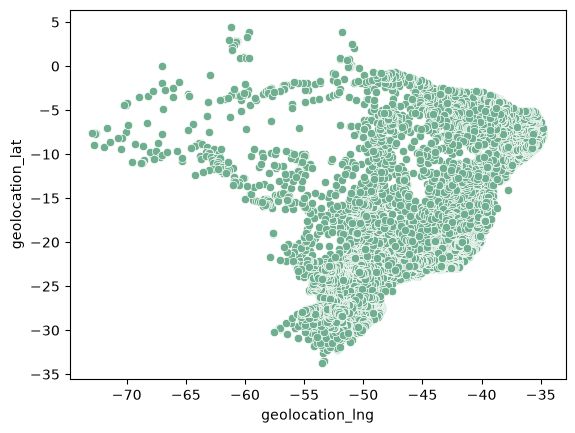

In [61]:
#all inside brazil as we removed 
sns.scatterplot(
data=geo_cleaned,x='geolocation_lng', y='geolocation_lat',color='#6FAF8F')

### Calculate distance

In [62]:
!pip install geopy

In [63]:
#function calculates distance from rows lat+lng
#https://www.geeksforgeeks.org/python/python-calculate-distance-between-two-places-using-geopy/
from geopy.distance import geodesic
def distance(row):
    seller=(row['geolocation_lat_seller'],row['geolocation_lng_seller'])
    customer=(row['geolocation_lat_customer'],row['geolocation_lng_customer'])
    if any(pd.isna(x) for x in seller + customer):
        return float('nan')
    
    return geodesic(seller,customer).km


In [64]:
items_cleaned['distance_km']= items_cleaned.apply(distance,axis=1)

In [65]:
items_cleaned['distance_km'].head(10)

0    301.773645
1    584.635144
2    311.548958
3    294.373438
4    647.195585
5    161.154582
6    484.851492
7    548.574524
8     53.057338
9     33.312783
Name: distance_km, dtype: float64

In [66]:
#aggrigate each order with related features to be used in final_df
order_features = items_cleaned.groupby('order_id').agg(
    #order info
    item_count=('order_item_id', 'count'),
    seller_count=('seller_id','nunique'),
    #prices
    price_sum=('price', 'sum'),
    freight_value_sum=('freight_value', 'sum'),
    #distance
    distance_max=('distance_km', 'max'),
    #product
    product_weight_g_max=('product_weight_g', 'max'),
    product_length_cm_max=('product_length_cm', 'max'),
    product_height_cm_max=('product_height_cm', 'max'),
    product_width_cm_max=('product_width_cm', 'max'),
    product_max_dim_cm_max=('product_max_dim_cm', 'max'),
    product_vol_cm_max=('product_vol_cm', 'max')
).reset_index()

In [70]:
order_features['order_id'].duplicated().sum() #no duplicates

np.int64(0)

In [71]:

final_df= orders_cleaned.merge(order_features,on='order_id',how='left')

In [72]:
final_df = final_df.merge(  customer_cleaned[['customer_id', 'customer_city', 'customer_state'] ],
    on='customer_id', how='left',validate='many_to_one')

In [73]:
# add purchase month and day
final_df['purchase_month']= final_df['order_purchase_timestamp'].dt.month
final_df['purchase_day']= final_df['order_purchase_timestamp'].dt.day_of_week


## Correlation between features

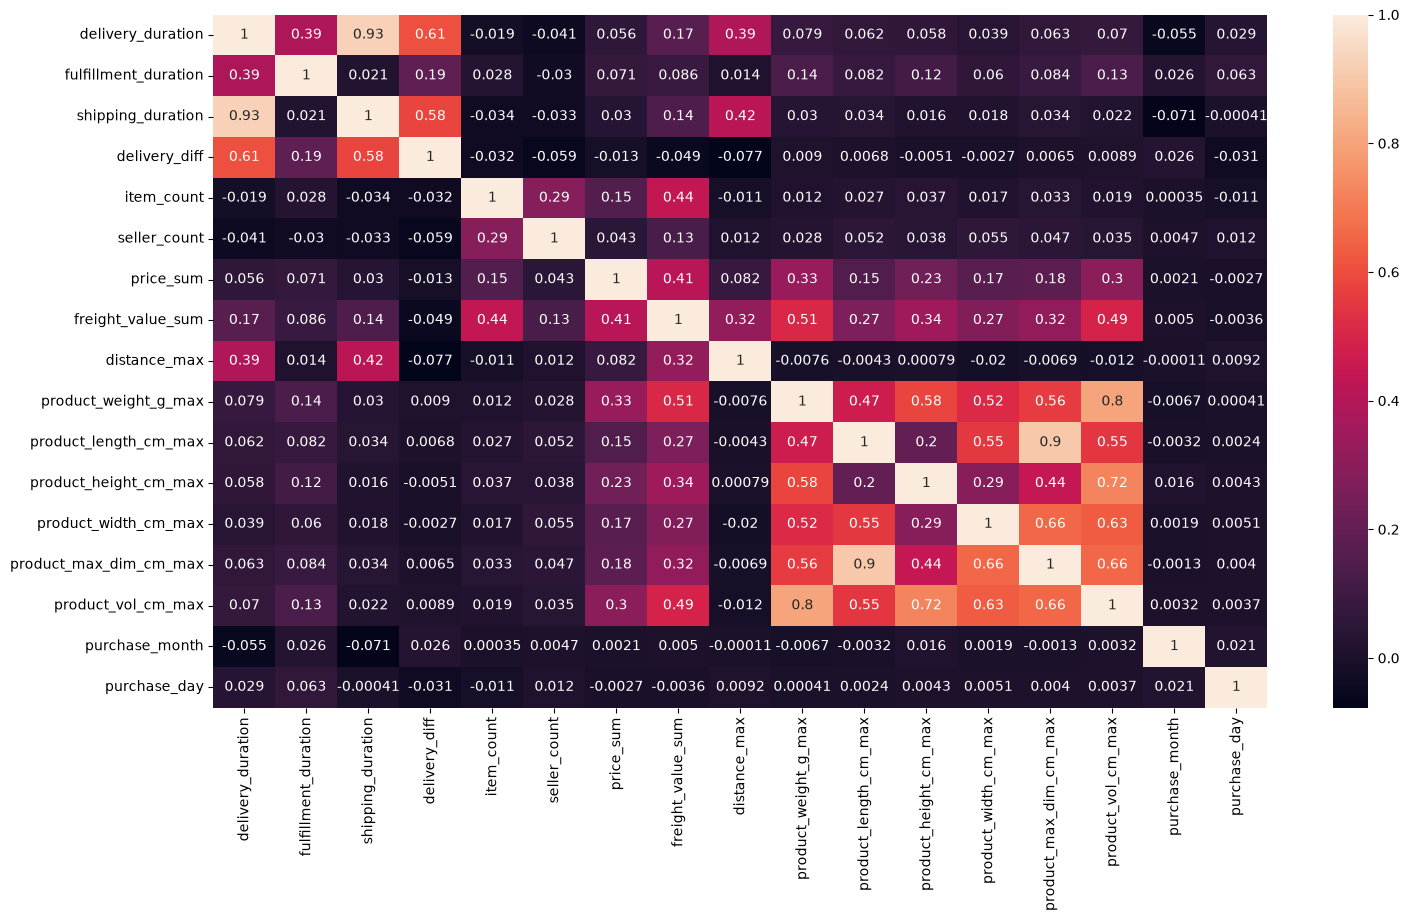

In [74]:
matrix= final_df.corr(numeric_only=True)
plt.figure(figsize=(17,9))
sns.heatmap(matrix, annot=True);

# Model Bulding

## Choosing featuers

In [75]:
final_df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'delivery_status', 'delivery_duration', 'fulfillment_duration',
       'shipping_duration', 'delivery_diff', 'item_count', 'seller_count',
       'price_sum', 'freight_value_sum', 'distance_max',
       'product_weight_g_max', 'product_length_cm_max',
       'product_height_cm_max', 'product_width_cm_max',
       'product_max_dim_cm_max', 'product_vol_cm_max', 'customer_city',
       'customer_state', 'purchase_month', 'purchase_day'],
      dtype='str')

In [76]:
cols = ['item_count','seller_count','price_sum','freight_value_sum','distance_max'
      ,'product_max_dim_cm_max','product_vol_cm_max','purchase_month','purchase_day']

In [77]:
final_df[cols].isna().sum().sort_values(ascending=False) #checking nulls 

distance_max              477
product_vol_cm_max         16
product_max_dim_cm_max     16
item_count                  0
seller_count                0
freight_value_sum           0
price_sum                   0
purchase_month              0
purchase_day                0
dtype: int64

## Splitting 

In [70]:
from sklearn.model_selection import train_test_split
x = final_df.drop(columns='delivery_duration')
y = final_df['delivery_duration']

#split1
x_train_val, x_test, y_train_val, y_test= train_test_split(x,y, test_size=0.2,random_state=42)
#split2 the train to train and val 
x_train, x_val, y_train, y_val = train_test_split(x_train_val,y_train_val, test_size=0.2,random_state=42)

In [71]:
#pipline
from sklearn.pipeline import make_pipeline #seq 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
num_pipe= make_pipeline(SimpleImputer(strategy='median'),StandardScaler())

In [72]:
#transform
from sklearn.compose import ColumnTransformer
preprocessing_pipe= ColumnTransformer(
    [
        ('num', num_pipe,cols ),
 
    ]
)
preprocessing_pipe

,transformers,"[('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [73]:
#fit lr
#main pipline
from sklearn.pipeline import  Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

#LR
lr_pipeline= make_pipeline(preprocessing_pipe,LinearRegression())
lr_pipeline.fit(x_train,y_train)
#KNN
knn_pipeline= make_pipeline(preprocessing_pipe,KNeighborsRegressor(n_neighbors=4))
knn_pipeline.fit(x_train,y_train)
#DT
dt_pipeline= make_pipeline(preprocessing_pipe,DecisionTreeRegressor())
dt_pipeline.fit(x_train,y_train)
#RF
rf_pipeline= make_pipeline(preprocessing_pipe, RandomForestRegressor(random_state=42))
rf_pipeline.fit(x_train,y_train)

,steps,"[('columntransformer', ...), ('randomforestregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## LR 

In [74]:
#prediction
from sklearn.metrics import mean_absolute_error
y_pred_val= lr_pipeline.predict(x_val)
LR_MAE=mean_absolute_error(y_val,y_pred_val) 
LR_MAE

5.629369339005281

## KNN

In [75]:
#prediction - val
from sklearn.metrics import mean_absolute_error
y_pred_val= lr_pipeline.predict(x_val)
mean_absolute_error(y_val,y_pred_val) 


5.629369339005281

In [76]:
#turning 
from sklearn.model_selection import GridSearchCV
knn_grid = {
    'kneighborsregressor__n_neighbors': [5, 10, 20, 30],
    'kneighborsregressor__weights': ['uniform', 'distance'],
    'kneighborsregressor__p': [1, 2]
}

knn_search = GridSearchCV(
    knn_pipeline,
    knn_grid,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

knn_search.fit(x_train, y_train)

,estimator,Pipeline(step...eighbors=4))])
,param_grid,"{'kneighborsregressor__n_neighbors': [5, 10, ...], 'kneighborsregressor__p': [1, 2], 'kneighborsregressor__weights': ['uniform', 'distance']}"
,scoring,'neg_mean_absolute_error'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...)]"


In [77]:
#prediction - val
from sklearn.metrics import mean_absolute_error
y_pred_val= knn_search.predict(x_val)
KNN_MAE=mean_absolute_error(y_val,y_pred_val) 
KNN_MAE

5.157297405297594

## DT

In [78]:
#Tuning
from sklearn.model_selection import GridSearchCV
dt_grid = {
      'decisiontreeregressor__max_depth': [5, 10, 15, 20],
    'decisiontreeregressor__min_samples_split': [2, 10, 20],
    'decisiontreeregressor__min_samples_leaf': [2, 5, 10]
}
dt_search =  GridSearchCV(
    dt_pipeline, dt_grid, cv=3, scoring='neg_mean_absolute_error',n_jobs=1)
dt_search.fit(x_train,y_train)

,estimator,Pipeline(step...Regressor())])
,param_grid,"{'decisiontreeregressor__max_depth': [5, 10, ...], 'decisiontreeregressor__min_samples_leaf': [2, 5, ...], 'decisiontreeregressor__min_samples_split': [2, 10, ...]}"
,scoring,'neg_mean_absolute_error'
,n_jobs,1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...)]"


In [79]:
dt_search.best_params_

{'decisiontreeregressor__max_depth': 5,
 'decisiontreeregressor__min_samples_leaf': 10,
 'decisiontreeregressor__min_samples_split': 10}

In [80]:
#prediction - val
from sklearn.metrics import mean_absolute_error
y_pred_val= dt_search.predict(x_val)
DT_MAE=mean_absolute_error(y_val,y_pred_val) 
DT_MAE

5.247714271084846

## RF

In [81]:
#tuning ( before 5.210)
from sklearn.model_selection import GridSearchCV
rf_grid = {
    'randomforestregressor__n_estimators': [100, 200],
    'randomforestregressor__max_depth': [10, 20],
    'randomforestregressor__min_samples_leaf': [2, 5]
}
rf_search= GridSearchCV(
    rf_pipeline, rf_grid, cv=3, scoring='neg_mean_absolute_error'
)
rf_search.fit(x_train,y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'randomforestregressor__max_depth': [10, 20], 'randomforestregressor__min_samples_leaf': [2, 5], 'randomforestregressor__n_estimators': [100, 200]}"
,scoring,'neg_mean_absolute_error'
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...)]"


In [82]:
#prediction - val
from sklearn.metrics import mean_absolute_error
y_pred_val= rf_search.predict(x_val)
RF_MAE=mean_absolute_error(y_val,y_pred_val) 
RF_MAE

5.070712996027374

In [83]:
rf_search.best_params_

{'randomforestregressor__max_depth': 20,
 'randomforestregressor__min_samples_leaf': 5,
 'randomforestregressor__n_estimators': 200}

## Voting - multi models

In [84]:
from sklearn.ensemble import VotingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import  Pipeline

voting_clf= make_pipeline (preprocessing_pipe, 
VotingRegressor(estimators=[
    ('dt',DecisionTreeRegressor()),
    ('knn', KNeighborsRegressor()),
    ('rf', RandomForestRegressor(random_state=42)) ]))

In [85]:
voting_clf.fit(x_train, y_train)

,steps,"[('columntransformer', ...), ('votingregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [86]:
#prediction - val
from sklearn.metrics import mean_absolute_error
y_pred_val= voting_clf.predict(x_val)
Voting_MAE=mean_absolute_error(y_val,y_pred_val) 
Voting_MAE

5.415149834758569

## Bagging -  one model

In [87]:
from sklearn.ensemble import AdaBoostRegressor

bagging_clf= make_pipeline (preprocessing_pipe, 
AdaBoostRegressor(estimator=RandomForestRegressor(max_depth=20),
                  n_estimators=50, random_state=42))
bagging_clf.fit(x_train, y_train)

,steps,"[('columntransformer', ...), ('adaboostregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [88]:
#prediction - val
from sklearn.metrics import mean_absolute_error
y_pred_val= bagging_clf.predict(x_val)
Bagging_MAE=mean_absolute_error(y_val,y_pred_val) 
Bagging_MAE

5.590315671033703

## Stackig

In [89]:
from sklearn.ensemble import StackingRegressor
staking_pipe= make_pipeline( preprocessing_pipe, StackingRegressor(
    estimators = [(
    'dt',DecisionTreeRegressor()),
    ('knn', KNeighborsRegressor()),
    ('rf', RandomForestRegressor(random_state=42)) ],
 final_estimator=LinearRegression(),
    cv=3 
)
                           )
                
staking_pipe.fit(x_train,y_train)

,steps,"[('columntransformer', ...), ('stackingregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [90]:
#prediction - val
from sklearn.metrics import mean_absolute_error
y_pred_val= staking_pipe.predict(x_val)
staking_MAE=mean_absolute_error(y_val,y_pred_val) 
staking_MAE

5.124849245765522

# Best Model (Evaluation)

In [72]:
mae_score = {
    'Linear Regression': LR_MAE,
    'KNN': KNN_MAE,
    'Decision Tree': DT_MAE,
    'Random Forest': RF_MAE,
    'Voting': Voting_MAE,
    'Bagging': Bagging_MAE,
    'Stacking': staking_MAE
}
mae_score=pd.Series(mae_score).sort_values(ascending=True)
mae_score.plot(kind='bar', color='#6FAF8F')
plt.title('Mean Absolute Error using Models');
plt.xlabel('Model')
plt.xticks(rotation=45)
plt.ylabel('Mean Absolute Error')
plt.show()

NameError: name 'LR_MAE' is not defined

In [92]:
print(mae_score)

Random Forest        5.070713
Stacking             5.124849
KNN                  5.157297
Decision Tree        5.247714
Voting               5.415150
Bagging              5.590316
Linear Regression    5.629369
dtype: float64


# Streamlit app 

In [137]:
import joblib
joblib.dump(rf_search.best_estimator_, "delivery.pkl")

['delivery.pkl']

In [143]:
%%writefile delivery_app.py
import streamlit as st
import pandas as pd
import joblib
from math import radians, sin, cos, asin, sqrt # i need it to cal langtide an latitude 

# Load model and data
model = joblib.load("delivery.pkl")
products = pd.read_csv("olist_products_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")

# Features used by the model
cols = [
    "item_count", "seller_count", "price_sum",
    "freight_value_sum", "distance_max",
    "product_max_dim_cm_max", "product_vol_cm_max",
    "purchase_month", "purchase_day"]

st.title("Brazilian Online Store")
st.write("Place your order and estimate your delivery time.")
# product data
product_info = items.groupby("product_id").agg({
    "price": "mean",
    "freight_value": "mean",
    "seller_id": "first"}).reset_index()

product_info = product_info.rename(columns={"freight_value": "shipping"})
products = pd.merge(products, product_info, on="product_id")
products = pd.merge(products,sellers[["seller_id", "seller_zip_code_prefix"]],on="seller_id", how="left")

# location data
geo["zip"] = (pd.to_numeric(geo["geolocation_zip_code_prefix"], errors="coerce").astype("Int64").astype(str).str.zfill(5))
geo = geo.groupby("zip").agg({
    "geolocation_lat": "mean",
    "geolocation_lng": "mean"}).reset_index()
geo = geo.rename(columns={
    "geolocation_lat": "latitude",
    "geolocation_lng": "longitude"})

# Choose products
st.subheader("1. Choose Your Products")
categories = {
    "Health and Beauty": "beleza_saude",
    "Beds and Bath": "cama_mesa_banho",
    "Computers": "informatica_acessorios",
    "Sports and Leisure": "esporte_lazer",
    "Watches and Gifts": "relogios_presentes",
    "Furniture": "moveis_decoracao",
    "Electronics": "eletronicos"}
selected_products = st.multiselect("Select products", list(categories.keys()) + ["Others"])
selected_rows = []

for i, name in enumerate(selected_products):
    if name == "Others":
        st.text_input("Enter product name", key="other_name")
        st.number_input(
            "Quantity for Others", min_value=1, value=1,
            key="quantity_other")
    else:
        category_products = products[
            products["product_category_name"] == categories[name]]
#user can choose the quantity of the prouducts 
       quantity = st.number_input(f"Quantity for {name}", min_value=1, value=1,key=f"quantity_{i}")
        
        if not category_products.empty:
            product = category_products.iloc[0].copy()
            product["quantity"] = quantity
            selected_rows.append(product)
selected = pd.DataFrame(selected_rows)

# Customer information
st.subheader("2. Customer Information")
name = st.text_input("Your Name")
state_names = {
    "AC": "Acre", "AL": "Alagoas", "AP": "Amapá",
    "AM": "Amazonas", "BA": "Bahia", "CE": "Ceará",
    "DF": "Distrito Federal", "ES": "Espírito Santo",
    "GO": "Goiás", "MA": "Maranhão", "MT": "Mato Grosso",
    "MS": "Mato Grosso do Sul", "MG": "Minas Gerais",
    "PA": "Pará", "PB": "Paraíba", "PR": "Paraná",
    "PE": "Pernambuco", "PI": "Piauí", "RJ": "Rio de Janeiro",
    "RN": "Rio Grande do Norte", "RS": "Rio Grande do Sul",
    "RO": "Rondônia", "RR": "Roraima", "SC": "Santa Catarina",
    "SP": "São Paulo", "SE": "Sergipe", "TO": "Tocantins"}

states = sorted(customers["customer_state"].dropna().unique())
state = st.selectbox("Select Brazilian State", states,format_func=lambda x: state_names.get(x, x))
cities = sorted(customers[customers["customer_state"] == state]
    ["customer_city"].dropna().unique())
city = st.selectbox("Select City", cities)
city_customers = customers[
    (customers["customer_state"] == state) &
    (customers["customer_city"] == city)]
zip_codes = pd.to_numeric(
    city_customers["customer_zip_code_prefix"], errors="coerce").dropna()

zip_code = (str(int(zip_codes.iloc[0])).zfill(5)
    if not zip_codes.empty 
            else "")

# Place order
if st.button("Order Now"):
    if not name.strip() or not selected_products:
        st.warning("Please complete all information.")
    elif "Others" in selected_products and not st.session_state.get(
        "other_name", "").strip():
        st.warning("Please enter your product name.")
    elif selected.empty:
        st.warning("Please choose an available product category.")
    elif not zip_code:
        st.warning("Could not find a ZIP code for this city.")
    else:
        item_count = int(selected["quantity"].sum())
        seller_count = selected["seller_id"].nunique()
        price_sum = (selected["price"] * selected["quantity"]).sum()
        shipping_sum = (
            selected["shipping"] * selected["quantity"]).sum()

        # Find delivery distance
        selected["seller_zip"] = (pd.to_numeric(selected["seller_zip_code_prefix"], errors="coerce").astype("Int64").astype(str).str.zfill(5))
        customer_location = geo[geo["zip"] == zip_code]
        distances = []

        if not customer_location.empty:
            for seller_zip in selected["seller_zip"]:
                seller_location = geo[geo["zip"] == seller_zip]
                if not seller_location.empty:
                    lat1 = customer_location.iloc[0]["latitude"]
                    lon1 = customer_location.iloc[0]["geolocation_lng"] if "geolocation_lng" in customer_location.columns else customer_location.iloc[0]["longitude"]
                    lat2 = seller_location.iloc[0]["latitude"]
                    lon2 = seller_location.iloc[0]["longitude"]
                    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
                    a = (sin((lat2-lat1)/2)**2 +cos(lat1)*cos(lat2)*sin((lon2-lon1)/2)**2)
                    distances.append(6371 * 2 * asin(sqrt(a)))

        if not distances:
            st.error("Could not calculate the delivery distance.")
        else:
            dimensions = selected[
                ["product_length_cm", "product_height_cm",
                 "product_width_cm"]].fillna(0)

            today = pd.Timestamp.today()
            order = pd.DataFrame([{
                "item_count": item_count,
                "seller_count": seller_count,
                "price_sum": price_sum,
                "freight_value_sum": shipping_sum,
                "distance_max": max(distances),
                "product_max_dim_cm_max": dimensions.max(axis=1).max(),
                "product_vol_cm_max": (
                    selected["product_length_cm"].fillna(0) *
                    selected["product_height_cm"].fillna(0) *
                    selected["product_width_cm"].fillna(0)
                ).max(),
                "purchase_month": today.month,
                "purchase_day": today.weekday()}])

            prediction = model.predict(order[cols])[0]
            # display orders 
            st.success("Order placed successfully!")
            st.write("Customer:", name)
            st.write("City:", city)
            st.write("State:", state_names.get(state, state))
            st.write(f"Product total: R$ {price_sum:.2f}")
            st.write(f"Shipping cost: R$ {shipping_sum:.2f}")
            st.write(f"Estimated delivery duration: {prediction:.1f} days")


Overwriting delivery_app.py


In [146]:
from sklearn.metrics import mean_absolute_error
import numpy as np
predictions = rf_search.predict(x_test)
mae = mean_absolute_error(y_test, predictions)
print("MAE:", round(mae, 1))
print("Actual average:", round(y_test.mean(), 2))
print("Predicted average:", round(predictions.mean(), 2))


MAE: 5.0
Actual average: 12.45
Predicted average: 12.6
